# Volume Factor Audit

A reproducible investigation of stock selection, rebalancing and profit concentration in an equity backtest.

**Default dataset: synthetic demonstration, not market evidence.** This notebook makes the accounting and experimental comparisons inspectable. Historical downloads and CSV snapshots are optional, explicit inputs.

## Research questions

1. Does dynamic volume-based selection improve the result relative to rebalancing the initial selected list?
2. How does monthly rebalancing of that fixed list compare with buying and holding it?
3. Which positions contribute to account P&L, and how sensitive are results to excluding a stock or changing volume units?

Signals use month-end information; target portfolios execute at the next trading-session close. The first return of a new position accrues after execution. All strategies use the same account model, assumed transaction-cost rate and initial capital.

Run the cells in order. Data loading, analysis and saving are separate so that saving an existing calculation does not require a new download.

## 1. Environment

Open this notebook from a checkout of the repository and select its Python environment. The source check verifies the packaged engine files; it is not a check of market-data provenance.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from uuid import uuid4
from copy import deepcopy
import importlib.metadata as package_metadata
import json
import platform
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

HERE = Path.cwd().resolve()
ROOT = next(
    (p for p in [HERE, *HERE.parents]
     if (p / "multifactor" / "audit.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the complete repository checkout.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from multifactor.audit import (
    Data, read_data, download, run_audit, save_run, verify_engines,
)
from multifactor.signals import demo_data

verify_engines()
environment = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "exchange_calendars": package_metadata.version("exchange-calendars"),
}
display(pd.Series(environment, name="version").to_frame())

,version
python,3.12.14
numpy,2.3.5
pandas,2.2.3
exchange_calendars,4.13.1


## 2. Configuration

- `demo` creates an offline synthetic dataset.
- `csv` loads an existing snapshot containing `close.csv` and `volume.csv`, with optional `source_close.csv` and `splits.csv`.
- `download` requests a new Yahoo snapshot and requires the optional download dependency. A new vendor download is not presumed identical to an earlier snapshot.

The end date is exclusive. `COST_BPS` applies to actual traded notional on both purchases and sales. CSV mode preserves its declared source; it does not infer that an uploaded snapshot is authentic market data.

In [2]:
MODE = "demo"
START = "2018-01-01"
END = "2025-01-01"
CSV_FOLDER = ROOT / "data" / "snapshot"

N_STOCKS = 10
COST_BPS = 10.0
INITIAL_CASH = 1_000_000.0
LEAVE_ONE_OUT = True

if MODE not in {"demo", "csv", "download"}:
    raise ValueError("MODE must be 'demo', 'csv', or 'download'.")

## 3. Load the selected dataset

There is no automatic fallback between modes. A missing price, invalid axis or unsupported response must be investigated rather than silently filled or removed. When prices are adjusted, account holdings are synthetic adjusted-price units rather than literal brokerage shares.

In [3]:
if MODE == "demo":
    close, volume = demo_data()
    data = Data(close, volume, close.copy(), volume * 0.0)
    data_source = {
        "mode": "demo",
        "source": "SYNTHETIC DEMO - NOT MARKET EVIDENCE",
    }
elif MODE == "csv":
    data = read_data(CSV_FOLDER)
    data_source = {
        "mode": "csv",
        "source": "CSV SNAPSHOT - PROVENANCE REQUIRES REVIEW",
        "input_folder_name": CSV_FOLDER.name,
    }
else:
    data = download(START, END)
    data_source = {
        "mode": "download",
        "source": "NEW YAHOO SNAPSHOT - FIXED SURVIVORSHIP-BIASED UNIVERSE",
        "requested_start": START,
        "requested_end_exclusive": END,
        "yfinance_version": package_metadata.version("yfinance"),
    }

print(data_source["source"])
display(pd.Series({
    "first_session": str(data.close.index[0].date()),
    "last_session": str(data.close.index[-1].date()),
    "sessions": len(data.close),
    "assets": len(data.close.columns),
}, name="dataset").to_frame())

SYNTHETIC DEMO - NOT MARKET EVIDENCE


,dataset
first_session,2024-01-02
last_session,2024-05-15
sessions,94
assets,12


## 4. Run the audit

The initial fixed list is selected at the first executable valid signal and then frozen. It is not chosen retrospectively from the final winners.

| Account | Selection | Rebalancing |
|---|---|---|
| `dynamic_volume` | Top-ranked volume signal at each eligible month-end | Monthly |
| `static_monthly` | Initial selected list, frozen | Monthly equal weight |
| `static_buy_hold` | Initial selected list, frozen | Initial purchase only |
| `universe_equal_weight` | Full supplied universe | Monthly equal weight |

The dollar-activity proxy is computed only when the required provider-basis close data are present. It is not audited traded-dollar volume or true float turnover.

A copy of the inputs and the parameters is retained with the calculation. Re-running only the save cell therefore saves the existing analysis rather than attaching a newly loaded dataset to old results.

In [4]:
verify_engines()
analysis_data = Data(**{
    name: None if getattr(data, name) is None else getattr(data, name).copy(deep=True)
    for name in ("close", "volume", "source_close", "splits")
})
analysis_source = deepcopy(data_source)
parameters = {
    "cost_bps": COST_BPS,
    "n_stocks": N_STOCKS,
    "initial_cash": INITIAL_CASH,
    "leave_one_out": LEAVE_ONE_OUT,
}
result = run_audit(
    analysis_data,
    cost_bps=parameters["cost_bps"],
    n=parameters["n_stocks"],
    initial=parameters["initial_cash"],
    leave_one_out=parameters["leave_one_out"],
)
metadata = {
    **analysis_source,
    **parameters,
    "lookback": 20,
    "ic_horizon": 20,
    "first_date": str(analysis_data.close.index[0]),
    "last_date": str(analysis_data.close.index[-1]),
    "tickers": list(analysis_data.close.columns),
    "execution": "month-end signal; next trading-session close execution",
    "limitations": [
        "Retrospective research design, not an untouched holdout",
        "Fixed universe with potential survivorship bias",
        "Provider price/volume adjustment basis not point-in-time certified",
        "Idealized close fills and assumed proportional costs",
        "Fractional adjusted-price units; zero cash interest; no terminal liquidation",
        "Historical float turnover not evaluated",
    ],
}
print(analysis_source["source"])
print(f"Maximum daily P&L reconciliation residual: {result['attribution_residual']:.3e}")
display(pd.Series(result["frozen"], name="initial selection").to_frame())

SYNTHETIC DEMO - NOT MARKET EVIDENCE
Maximum daily P&L reconciliation residual: 2.992e-10


,initial selection
signal_date,2024-01-31 00:00:00
execution_date,2024-02-01 00:00:00
names,"[S07, S01, S04, S09, S05, S03, S06, S08, S02, ..."
rule,"first valid signal, frozen thereafter"


## 5. Compare selection and rebalancing

CAGR describes compounded growth; its difference between strategies is reported in **percentage points**. Sharpe uses arithmetic mean daily return with zero risk-free rate. The information ratio uses the full-universe equal-weight account as its benchmark.

These comparisons isolate design choices conditional on this dataset and account model. They are not statistical-significance tests. In demo mode, every performance number below is a synthetic example.

,n_days,total_return,cagr,sharpe_rf_zero,ir_vs_universe,max_drawdown,fees
strategy,,,,,,,
dynamic_volume,94,0.065611,0.185734,3.755301,1.954828,-0.018910,2317.874072
static_monthly,94,0.064655,0.182885,3.842786,1.691072,-0.019084,1070.430364
static_buy_hold,94,0.066243,0.187623,3.942989,1.941615,-0.018064,999.000999
universe_equal_weight,94,0.053672,0.150456,3.492165,NaN,-0.013569,1073.442407
dollar_activity_proxy,94,0.057951,0.163024,3.371706,0.644412,-0.019227,2087.955085


Dynamic selection minus fixed-list monthly CAGR: +0.2850 pp
Fixed-list monthly minus fixed-list buy-and-hold CAGR: -0.4738 pp


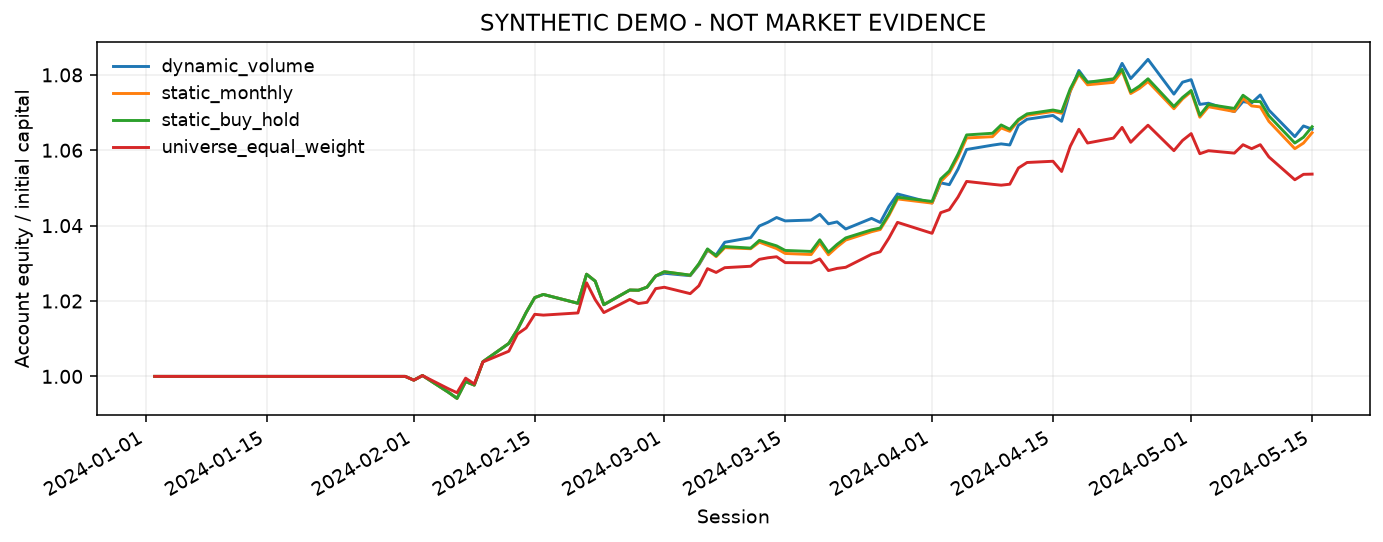

In [5]:
full = result["comparison"].query("period == 'full'").set_index("strategy")
display(full[[
    "n_days", "total_return", "cagr", "sharpe_rf_zero",
    "ir_vs_universe", "max_drawdown", "fees",
]].round(6))

selection_gap = full.loc["dynamic_volume", "cagr"] - full.loc["static_monthly", "cagr"]
rebalancing_gap = full.loc["static_monthly", "cagr"] - full.loc["static_buy_hold", "cagr"]
print(f"Dynamic selection minus fixed-list monthly CAGR: {100 * selection_gap:+.4f} pp")
print(f"Fixed-list monthly minus fixed-list buy-and-hold CAGR: {100 * rebalancing_gap:+.4f} pp")

fig, ax = plt.subplots(figsize=(10, 4))
for name in ("dynamic_volume", "static_monthly", "static_buy_hold", "universe_equal_weight"):
    account = result["accounts"][name]
    (account.daily.equity_after_trade / parameters["initial_cash"]).plot(ax=ax, label=name)
ax.set_ylabel("Account equity / initial capital")
ax.set_xlabel("Session")
ax.set_title(analysis_source["source"])
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## 6. Reconcile P&L attribution

For each stock, gross P&L uses the previous close's units and the subsequent price change; fees are allocated from the actual trade ledger.

\[
\text{contribution}_i =
\frac{\text{net P\&L}_i}{\text{initial capital}}.
\]

The contributions add to the account's cumulative simple return. They do not add to CAGR and are not risk contributions or independent alpha estimates.

,gross_pnl,fees,net_pnl,contribution_to_total_return
ticker,,,,
S08,20980.163794,111.081889,20869.081905,0.020869
S05,15404.978576,113.512037,15291.466539,0.015291
S07,11270.540036,101.564079,11168.975957,0.011169
S04,9332.447219,318.463743,9013.983476,0.009014
S09,9156.513895,210.294525,8946.219370,0.008946
S00,7243.208450,103.416053,7139.792397,0.007140
S03,4182.293332,310.420662,3871.872670,0.003872
S10,3174.085869,316.844447,2857.241422,0.002857
S11,-666.894402,217.463473,-884.357876,-0.000884


Stock-level net P&L: 65,610.5012
Account equity change: 65,610.5012


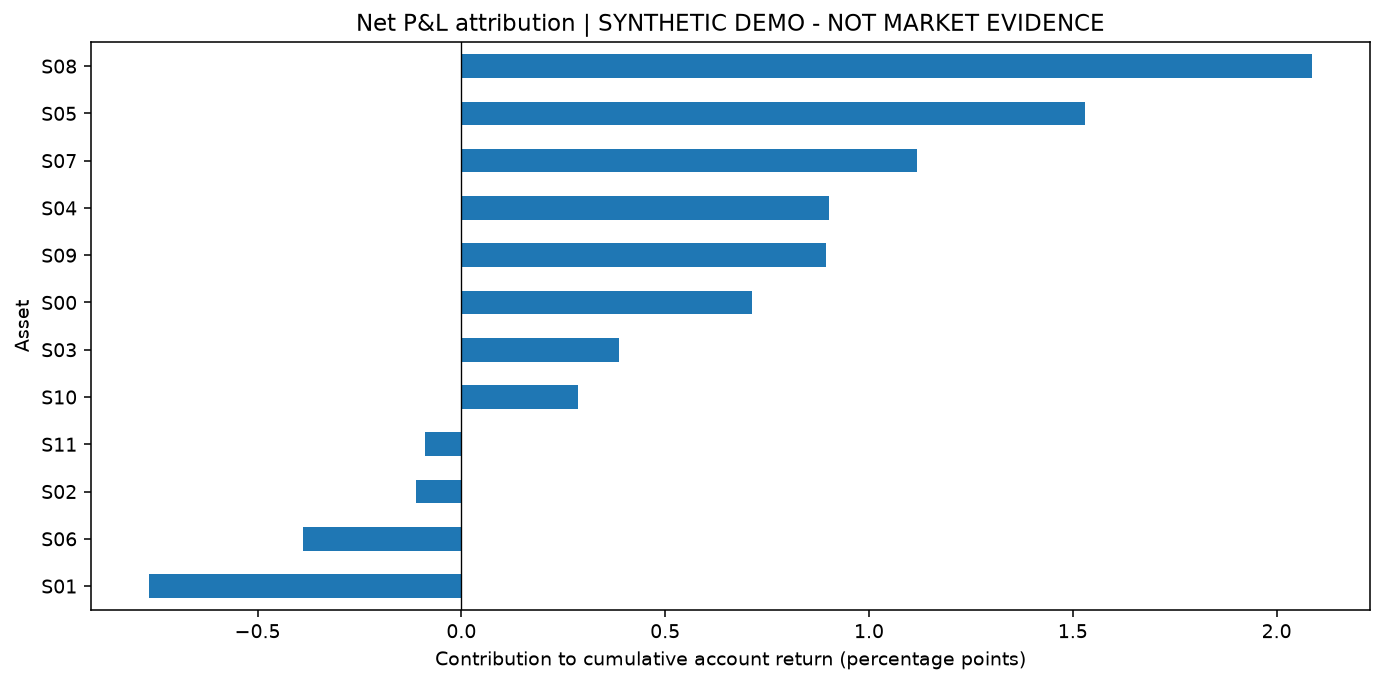

In [6]:
attribution = result["attribution"].sort_values("net_pnl", ascending=False)
display(attribution.round(6))

account_change = (
    result["accounts"]["dynamic_volume"].daily.equity_after_trade.iloc[-1]
    - parameters["initial_cash"]
)
attributed_change = float(attribution["net_pnl"].sum())
assert np.isclose(
    attributed_change, account_change,
    rtol=0, atol=1e-8 * parameters["initial_cash"],
)
print(f"Stock-level net P&L: {attributed_change:,.4f}")
print(f"Account equity change: {account_change:,.4f}")

fig, ax = plt.subplots(figsize=(10, 5))
attribution["contribution_to_total_return"].mul(100).sort_values().plot.barh(ax=ax)
ax.set_xlabel("Contribution to cumulative account return (percentage points)")
ax.set_ylabel("Asset")
ax.set_title("Net P&L attribution | " + analysis_source["source"])
ax.axvline(0, color="black", linewidth=0.7)
fig.tight_layout()
plt.show()

## 7. Leave-one-out and data-definition sensitivity

Removing a stock reruns selection, allocation and fees on the reduced universe. The resulting performance change is a different quantity from that stock's P&L in the original account.

The unit stress test doubles one stock's entire volume series to expose rank dependence on share-volume units. This is a sensitivity experiment, not a proposed split correction. True float turnover remains untested because verified historical float and release timestamps are unavailable.

In [7]:
print("Leave-one-out: counterfactual reruns")
if result["leave_one_out"].empty:
    print("Disabled for this run.")
else:
    display(result["leave_one_out"][[
        "excluded", "cagr", "cagr_change_vs_original", "mean_rank_ic",
    ]].sort_values("cagr_change_vs_original").round(6))

print("Share-volume unit sensitivity")
display(result["unit_stress"].sort_values(
    "changed_selections", ascending=False,
).reset_index(drop=True))

print("Variable definitions and evaluation status")
display(result["definitions"])

print("Provider-reported split events")
display(result["split_audit"].head(20))

Leave-one-out: counterfactual reruns


,excluded,cagr,cagr_change_vs_original,mean_rank_ic
8,S08,0.130365,-0.055369,0.106061
5,S05,0.146021,-0.039714,0.066667
7,S07,0.158835,-0.026899,0.006061
4,S04,0.163859,-0.021875,0.003030
9,S09,0.170458,-0.015276,0.057576
0,S00,0.170660,-0.015074,0.081818
10,S10,0.172991,-0.012744,-0.039394
3,S03,0.179780,-0.005955,-0.039394
11,S11,0.191047,0.005313,-0.030303
2,S02,0.195585,0.009850,0.021212


Share-volume unit sensitivity


,ticker_scaled,multiplier,changed_selections,n_compared
0,S11,2.0,2,4
1,S10,2.0,2,4
2,S03,2.0,1,4
3,S04,2.0,1,4
4,S09,2.0,1,4
5,S06,2.0,1,4
6,S00,2.0,0,4
7,S01,2.0,0,4
8,S02,2.0,0,4
9,S05,2.0,0,4


Variable definitions and evaluation status


,signal,status,meaning
0,share_volume,RUN,log1p(mean20 provider share volume)
1,true_float_turnover,NOT_RUN,No verified historical float and publication t...
2,dollar_activity_proxy,RUN,"mean20 provider Close*Volume; proxy, not audit..."


Provider-reported split events


,date,ticker,split_ratio,volume_median_before5,volume_median_after5,after_before_ratio


## 8. Save a new run without overwriting earlier work

Each execution of this cell creates a new output directory. It writes the calculation's input snapshot, account and trade ledgers, comparison tables, attribution and a run manifest with file hashes.

The save cell does not download data or recompute the audit. Save the notebook separately in Jupyter to retain the displayed tables, figures and interpretation.

In [8]:
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ") + "_" + uuid4().hex[:8]
RUN_DIR = ROOT / "outputs" / run_id
save_run(RUN_DIR, analysis_data, result, metadata)

print("Saved:", RUN_DIR.relative_to(ROOT))
print("Source:", analysis_source["source"])
print("Manifest:", (RUN_DIR / "RUN_INFO.json").relative_to(ROOT))

Saved: outputs/20261123T095620_429374Z_3333b00e
Source: SYNTHETIC DEMO - NOT MARKET EVIDENCE
Manifest: outputs/20261123T095620_429374Z_3333b00e/RUN_INFO.json


## Interpretation and limitations

The default run demonstrates that the controls, holdings accounting and P&L attribution can be inspected and reconciled. It supplies no evidence of a profitable market strategy.

For a historical-market run, report the observed effect, the relevant control and the unresolved assumptions together. In particular:

- A higher retrospective CAGR is not evidence of statistical significance or persistent alpha.
- A concentration of net profit in a few names is not a decomposition of portfolio risk.
- Year-by-year tables and retrospective partitions do not create an untouched holdout.
- A fixed list of surviving equities, vendor adjustments, idealized close execution and assumed fees constrain interpretation.

A stronger empirical evaluation would require a point-in-time universe and data definitions, realistic execution assumptions, and an evaluation sample that has not guided strategy selection.

### Optional regression checks

The cell below uses the current notebook kernel. Enabling it records the regression-suite output here; leaving it disabled makes no claim that tests were executed in this notebook.

In [9]:
RUN_TESTS = False

if RUN_TESTS:
    check = subprocess.run(
        [sys.executable, "-m", "pytest", "-q", "tests"],
        cwd=ROOT, capture_output=True, text=True,
    )
    print(check.stdout)
    if check.returncode:
        print(check.stderr)
        raise RuntimeError(f"Regression suite failed with exit code {check.returncode}.")
else:
    print("Regression suite not run in this notebook.")

Regression suite not run in this notebook.
